# Lecture 31 - Maps with GeoPandas
### EES 3350/5350 · Python in Earth Science · Wednesday, November 16, 2026 

You've plotted the 2021 Nashville flood as hydrographs, as volumes, and as runoff depths. But you've never plotted **where**: where are teh gauges, what land drains to each one, and where does the water go when it leaves the channel?

Today's tool is **GeoPandas**: pandas, plus a column that holds **shapes**. Everything you know about DataFrames still works.

**Learning Objectives**
- read map failes into a **GeoDataFrame**, and recognize points, lines, and polygons
- layer several datasets into one map
- cehck a dataset's **coordinate reference system (CRS)**, and convert it with `.to_crs()`
- measure areas correctly, and check them against published numbers
- color a map by a column, add a basemap, and **save a map** you could print

---
## Part 0 : set up

You installed `geopandas` and `contextily` earlier. If the next cell gives `ModuleNotFoundError`, run Monday's `install_packages` notebook again.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as cx

maps = "../../course-materials/week13/maps/"
usgs = "../../course-materials/week11/usgs/"

---
## Part 1 : a GeoDataFrame is a DataFrame with shapes
`gpd.read_file()` reads map files (GeoJSON, shapefiles, zipped shapefiles, GeoPackages...) the way `pd.read_csv()` reads tables:

In [2]:
gauges = gpd.read_file(maps + "gauges.geojson")

print(type(gauges))
gauges

<class 'geopandas.geodataframe.GeoDataFrame'>


,id,name,short_name,geometry
0,USGS-03431500,"CUMBERLAND RIVER AT NASHVILLE, TN",Cumberland,POINT (-86.77268 36.1615)
1,USGS-03434500,"HARPETH RIVER NEAR KINGSTON SPRINGS, TN",Harpeth,POINT (-87.09889 36.122)
2,USGS-03431060,"MILL CREEK AT THOMPSON LANE, NEAR WOODBINE, TN",Mill Creek,POINT (-86.71905 36.11757)


##### It looks like a DataFrame because it **is** one, which means `.head()`, masks, `groupby`, and `merge` all work. 

The new piece is the **last column: `geometry`**. Each row's geometry is a **shape**, here a `POINT` with two numbers: longitude, then latitude. (NOTE THE ORDER: **x first**, like every plot you've made)

### Three kinds of shapes
Map data that's made of shapes is called **vector** daya. There are three kinds, and today's map uses all three:

|**shape**|**what it is**|**today's files**|
|:--|:--|:--|
|**point**| one location | `gauges.geojson`: the three USGS gauges |
|**line**| connected points | `cumberland.geojson`, `tributaries.geojson`|
|**polygon**| a closed area | `harpeth_basin.geojson`, `millcreek_basin.gejson`, the `davidson_count` shapefile, `davidson_floodplain.zip`|

![point, line, polygon](../figures/pnt_line_poly.png)

(The other kind of map data is **gridded**, or **raster** data, like a DEM: a grid of numbers. That'll come after Thanksgiving.)

<span style="font-size:0.85em;color:#6b7a8d;"><em>Data: gauges, watersheds, and river lines from the USGS Network Linked Data Index (NLDI), based on NHDPlus V2. Davidson County from the U.S. Census Bureau 2024 cartographic boundary files. Flood zones from FEMA's National Flood Hazard Layer (NFHL), simplified for this course.</em></span>

In [4]:
rivers = gpd.read_file(maps + "cumberland.geojson")
tributaries = gpd.read_file(maps + "tributaries.geojson")

print(rivers.geom_type.unique())
print(len(tributaries), "tributary pieces")

<StringArray>
['LineString']
Length: 1, dtype: str
1648 tributary pieces


### Plotting: `.plot()` works on a GeoDataFrame

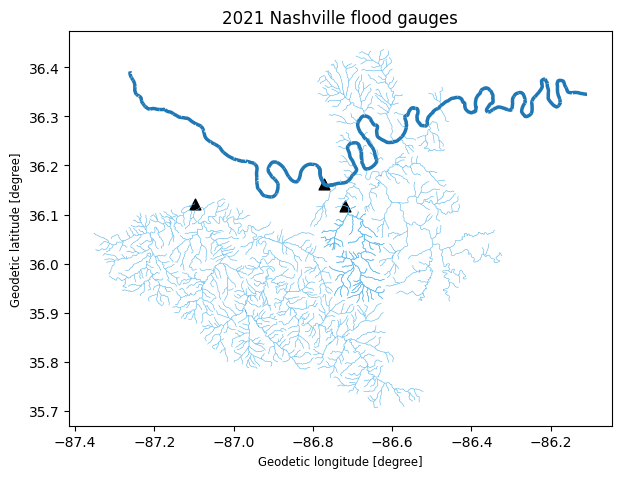

In [5]:
fig, ax = plt.subplots(figsize=(7,7))

tributaries.plot(ax=ax, color="#56B4E9", linewidth=0.4)
rivers.plot(ax=ax, color="tab:blue", linewidth=2.5)
gauges.plot(ax=ax, color="black", marker="^", markersize=60)

ax.set_title("2021 Nashville flood gauges");

#### Something slightly different when plotting with DataFrames or GeoDataFrames
To plot a lot of different things on the same axis *on a map*, you can't just do `ax.plot`. Pandas and GeoPandas have their own versions of the `.plot` function where you put the (Geo)DataFrame first and then use it, so:
```python
tributaries.plot(...)
```
You start from the data and call `data.plot(ax=ax)` where `ax=ax` tells GeoPandas which set of axes to draw on. For maps, without `ax=`, it will make a brand-new figure every time. Layering only works when every layer draws onto the same axis.

```python
fig, ax = plt.subplots()
rivers.plot(ax=ax)
#           ↑   ↑
#           │   └── your variable: the axes you just made
#           └────── the name of .plot()'s keyword argument
```
The axis numbers are longitude and latitude, in **degrees**.
</div>

### Two file formats: GeoJSON and shapefiles
The gauges and rivers came from the USGS as **GeoJSON** (`.geojson`): one text file per dataset. The county comes from the Census Bureau as a `shapefile`, the most common map format you'll find online. A shapefile is reallyu **several files** with the same name and different endings, and they only work together:

In [6]:
!ls ../../course-materials/week13/maps/davidson_county/

davidson_county.cpg
davidson_county.dbf
davidson_county.prj
davidson_county.shp
davidson_county.shx


|**file**|**what it holds**|
|:--|:--|
|`.shp`|the shapes themselves|
|`.shx`|an index, so the shapes can be found quickly|
|`.dbf`|the attribute table: the columns you see in the GeoDataFrame|
|`.prj`|the **CRS**: what the coordinates mean|
|`.cpg`|which text encoding the table uses (optional)|

You read a shapefile by pointing at the `.shp`, and GeoPandas finds the others in the same folder. Shapefiles are often shared as one `.zip`, and `gpd.read_file()` can read the zip directly, without unzipping (you'll do that in Exercise 3).

<div class="alert alert-danger">

**Common Error**: Copying or emailing **only** the `.shp` file. Without the `.dbf` and `.prj`, you lose the columns and the CRS, and the error messages are confusing. **Always keeep a shapefile's files together,** or zip them together.
    
</div>

<div class="alert alert-info">

### Exercise 1 : add the watersheds and the county

Read the two watershed files and the county file. You'll need to explore your folder to find the right names. Then plot them.
    
</div>

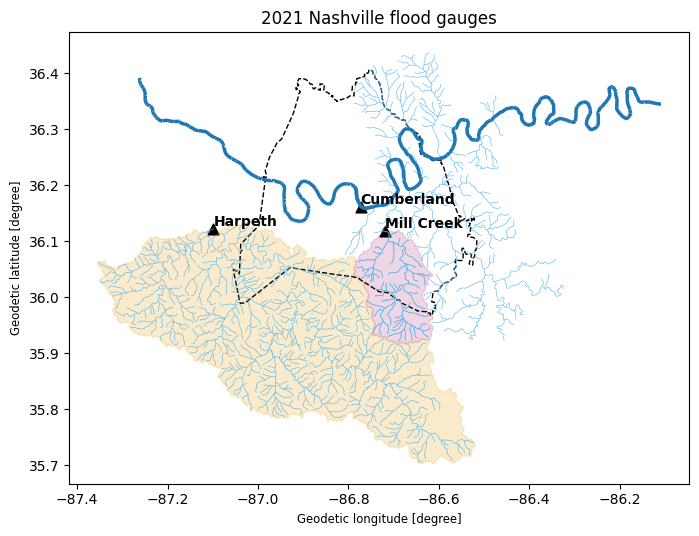

In [9]:
# read in the files
harpeth_basin = gpd.read_file(maps + "harpeth_basin.geojson")
mill_basin = gpd.read_file(maps + "millcreek_basin.geojson")
county = gpd.read_file(maps + "davidson_county/davidson_county.shp")

# add them to the plot
fig, ax = plt.subplots(figsize=(8,8))

harpeth_basin.plot(ax=ax, color="#E69F00", alpha=0.2, edgecolor="#E69F00")  # NEW: use of gdf.plot
mill_basin.plot(ax=ax, color="#CC79A7", alpha=0.3, edgecolor="#CC79A7")
county.boundary.plot(ax=ax, color="black", linewidth=1, linestyle="--")
tributaries.plot(ax=ax, color="#56B4E9", linewidth=0.4)
rivers.plot(ax=ax, color="tab:blue", linewidth=2.5)
gauges.plot(ax=ax, color="black", marker="^", markersize=60)

# adding text
xs = gauges.geometry.x       # NEW : every point's x (longitude)
ys = gauges.geometry.y       # NEW : every point's y (latitude)
names = gauges["short_name"]

for x, y, name in zip(xs, ys, names):
    ax.text(x, y, name, ha="left", va="bottom", fontweight="bold")

ax.set_title("2021 Nashville flood gauges");

#### ...okay but that plotted a filled in polygon...we need a slight change if we want to plot just the polygon's outline:
```python
county.boundary.plot(ax=ax, color="black", linewidth=1, linestyle="--")
```
This gives you a **new GeoSeries** holding only the county's outline turned into a **line**.

<div class="alert alert-success">

**Tip:** How do you know what goes after the dot?

No one memorizes these. There are three ways to find them:
1. **Tab completion.** Type `county.` and press **Tab**. Jupyter lists everything a GeoDataFrame can do. Type a few letters first (`county.bo` + Tab) to narrow the list.
2. **Ask Python.** Put a `?` after the name and run the cell: `county.boundary?` shows a short description
3. **The documentation.** Search "geopandas boundary" and the GeoPandas user guide will come up. The documentation for any package lists everything you can put after the dot.

**Some have parentheses and some don't**. 
- `.boundary`, `.area`, `.crs`, and `.x` have no `()` because they're **attributes**, information the GeoDataFrame already knows about itself, so you just look them up.
- `.plot()` and `.to_crs()` have `()` because they're **methods**, actions that take arguments.

This is the same pattern as pandas: `df.columns` (no parenteses) vs. `df.head()`.
    
</div>

---
## Part 2 : coordinate reference systems (CRS)

Every GeoDataFrame knows what its coordinates **mean**: its **coordinate reference system**, or CRS.

In [10]:
print(gauges.crs)
print(county.crs)

EPSG:4326
EPSG:4269


From this output, we can tell that both are in **degrees** of latitude and longitude.
- `EPSG:4326` (called WGS 84, what GPS uses)
- `EPSG:4269` (NAD83, used by many US agencies)

They differ by about meter here, so they line up fine on a map. An **EPSG code** is just an I*D number for a CRS; you can look up any of them at https://epsg.io.

Degrees are great for saying **where** something is. They're terrible for measuring **how big** something is: a degree of longitude is about 111 km at the equator, about 90 km in Nashville, and 0 km at the poles. To measure distances or areas, convert to a **projected** CRS, measured in **meteres**.

For Tennessee, a good choice is **UTM zone 16N** (`EPSG:32616`). UTM splits the world into 60 north-sourth strips, and inside its strip, each one is accurate to well under 1%.

- `.to_crs()` gives back a **new** GeoDataFrame with every coordinate converted

In [11]:
mill_utm = mill_basin.to_crs(epsg=32616)

print(mill_basin.geometry.iloc[0].bounds) # degrees
print(mill_utm.geometry.iloc[0].bounds)   # meters

(-86.789874593, 35.915527513, -86.61404425199999, 36.120973241)
(518928.1010652193, 3974623.095384571, 534808.4002295348, 3997410.975315749)


Every coordinate has now been converted from degrees to meters east and north. The shape is the same; only the numbers describing it have changed.

- `.bounds` gives the shape's edges in the order: `(west, south, east, north)`

<div class="alert alert-danger">

**Common Error**: Layers in **different** CRSs don't line up, and nothing warns you. Run the cell below: the county (in meters) and the gauges (in degrees) end up in completely different places, because GeoPandas plots the raw numbers.

<center><b>Check `.crs` on every layer, and convert them all to the same one before you plot together.</b></center>
    
</div>

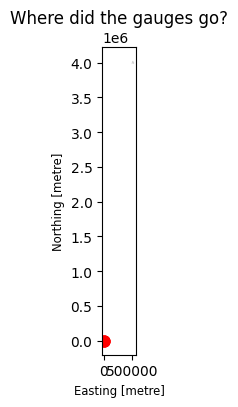

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))

county.to_crs(epsg=32616).plot(ax=ax, color="lightgray")
gauges.plot(ax=ax, color="red", markersize=60) # still in degrees!
ax.set_title("Where did the gauges go?");

The county is drawn hundresds of thousands of "units" from zero, and the three gauges are grammed into a tiny red do near (-87, 36). Two coordinate systems, one axes.

---
## Part 3 : areas, checked aginst the USGS

Once a layer is in meters, `.area` gives each polygon's area in **square meters**:

In [17]:
mill_utm.area.iloc[0]

np.float64(244316425.3956545)

In [13]:
area_m2 = mill_utm.area.iloc[0]

area_km2 = area_m2 /1e6
area_sqmi = area_m2 / 2.59e6   # 1 square mile = 2.59 million m^2

print(f"Mill Creek watershed: {area_km2:.0f} km2 = {area_sqmi:.0f} square miles")

Mill Creek watershed: 244 km2 = 94 square miles


<div class="alert alert-danger">

**Common Error**: Computing `.area` while the data is still in **degrees**. GeoPandas warns you (`UserWarning: Geometry is in a geographic CRS`), but it still gives an answer: in "square degrees", which aren't a real unit of area. 

<center><b>Always `.to_crs()` to meters first.</b></center>
    
</div>

<div class="alert alert-info">

### Exercise 2 : do our watersheds match the USGS?

The `_site.csv` files from Lecture 25 list each gauge's **drainage area** (in square miles), as published by the USGS. Compute both watersheds' areas from teh polygons and compare.
    
</div>

In [18]:
names = ["harpeth", "millcreek"]
basins = [harpeth_basin, mill_basin]

for name, basin in zip(names, basins):
    basin_utm = basin.to_crs(epsg=32616)
    map_sqmi = basin_utm.area.iloc[0] / 2.59e6

    site = pd.read_csv(usgs + name + "_site.csv")
    usgs_sqmi = site["drainage_area"][0]

    print(f"{name:10s} map: {map_sqmi:6.1f} sq mi    USGS: {usgs_sqmi:6.1f} sq mi    "
    f"difference: {(map_sqmi - usgs_sqmi) / usgs_sqmi * 100:+.1f}%")

harpeth    map:  682.2 sq mi    USGS:  683.0 sq mi    difference: -0.1%
millcreek  map:   94.3 sq mi    USGS:   93.4 sq mi    difference: +1.0%


A match within a few percent means the map's watershed and the USGS's agree: they were drawn from different elevation data, so small differences are normal. A **big** difference means the two aren't describing the same area. Here, the watershed outlines come from the national river dataset (NHDPlus) that's built form pieces called **catchments**, and an outline can end on the bottom of the gauge's catchment instead of exactly at the gauge. **Checking your map against a published number is how you catch that.**

---
## Part 4 : color by a column

`.plot(column="...")` colors each shape by the values in one column, like `c=` in a scatter plot. Let's color the gauges by how hard each one flooded: the **peak discharge per square mile**, form Lecture 25.

First, let's build that table again, but one step at a time:

In [19]:
rows = []
for name in ["cumberland", "harpeth", "millcreek"]:
    daily = pd.read_csv(usgs + name + "_daily.csv")
    site = pd.read_csv(usgs + name + "_site.csv")

    peak = daily["value"].max()
    area = site["drainage_area"][0]
    rows.append({"id": site["id"][0], "peak_per_sqmi": peak / area})

flood = pd.DataFrame(rows)
flood

,id,peak_per_sqmi
0,USGS-03431500,9.567517
1,USGS-03434500,63.250366
2,USGS-03431060,114.561028


Now `flood` is an ordinary DataFrame with one row per gauge, and its `id` column matches the `id` column in `guages`. 

You know how to join two tables on a shared key:

In [20]:
gauges = gauges.merge(flood, on="id")

gauges[["short_name", "peak_per_sqmi", "geometry"]]

,short_name,peak_per_sqmi,geometry
0,Cumberland,9.567517,POINT (-86.77268 36.1615)
1,Harpeth,63.250366,POINT (-87.09889 36.122)
2,Mill Creek,114.561028,POINT (-86.71905 36.11757)


**`.merge` worked on GeoDataFrame exactly as it would on a DataFrame: the result just maintains its `geometry`**

<center><span style="font-size: 20px;">A map is just a table with a shape in each row.</span>

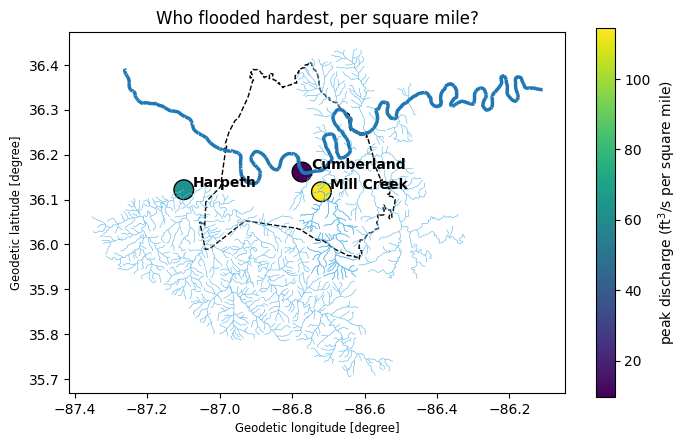

In [21]:
fig, ax = plt.subplots(figsize=(8, 8))

county.boundary.plot(ax=ax, color="black", linewidth=1, linestyle="--")
tributaries.plot(ax=ax, color="#56B4E9", linewidth=0.4)
rivers.plot(ax=ax, color="tab:blue", linewidth=2.5)
gauges.plot(ax=ax, column="peak_per_sqmi", cmap="viridis", markersize=200,   # NEW: plotting a single column from a GeoDataFrame
            edgecolor="black", legend=True,
            legend_kwds={"label": "peak discharge (ft$^3$/s per square mile)", "shrink":0.6})


# adding text
xs = gauges.geometry.x       
ys = gauges.geometry.y       
names = gauges["short_name"]

for x, y, name in zip(xs, ys, names):
    ax.text(x + 0.025, y, name, ha="left", va="bottom", fontweight="bold")

ax.set_title("Who flooded hardest, per square mile?");

---
## Part 5 : a basemap and saving a map to print

A **basemap** puts streets, towns, and terrain underneath your data.

- `contextily` downloads map tiles from the internet, and those tiles use one particular projected CRS: **Web Mercator**(`EPSG:3857`).

So we need to convert every layer to 3857 first:

In [22]:
web = 3857

county_w = county.to_crs(epsg=web)
rivers_w = rivers.to_crs(epsg=web)
tribs_w = tributaries.to_crs(epsg=web)
gauges_w = gauges.to_crs(epsg=web)

We imported contextily as `cx`.
- `cx.add_basemap(ax, source=...)` will fill in the background with map tiles for exactly the area on your axes

You should call this **after** the layers (and after any zoom)

- `ax.set_axis_off()` hides the tick labels

This is useful because the ticks are now meters on Web Mercator and wouldn't mean much to a reader. The small text in the corner credits the tile provider; leave that in.

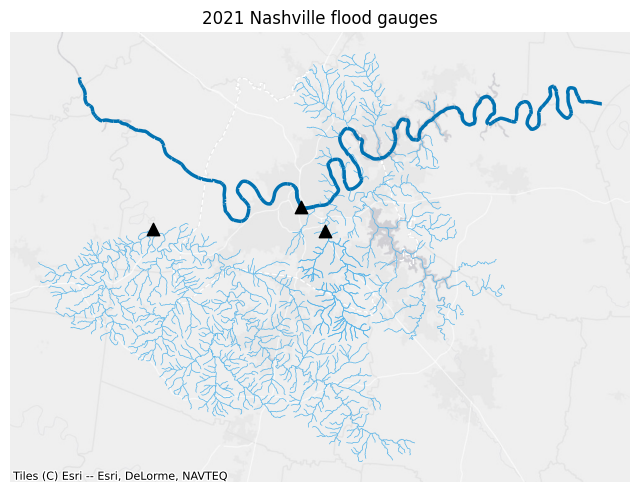

In [27]:
fig, ax = plt.subplots(figsize=(8, 8))

county_w.boundary.plot(ax=ax, color="white", linewidth=1, linestyle="--")
tribs_w.plot(ax=ax, color="#56B4E9", linewidth=0.5)
rivers_w.plot(ax=ax, color="#0072B2", linewidth=2.5)
gauges_w.plot(ax=ax, color="black", marker="^", markersize=80, zorder=5)

cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas)

ax.set_axis_off()
ax.set_title("2021 Nashville flood gauges");

#### Other basemaps:

- For high-resolution satellite imagery:
```python
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)
```
- For a topographic map with some labels:
```python
cx.add_basemap(ax, source=cx.providers.WorldTopoMap)
```
Another option to make sure that the basemap is using the right CRS is to add the following `crs` parameter and replace `df` with your dataframe that you're plotting
```python
crs=df.crs
```
##### Contextily will automatically zoom, but sometimes it's blurry. You can change the zoom with the `zoom` parameter:
```python
zoom=5
```

### Saving a map your could print
- `fig.savefig()` writes the figure to a file. For printing, use a high **dpi**, like 300:

In [28]:
fig.savefig("nashville_gauges_map.png", dpi=300, bbox_inches="tight")

<div class="alert alert-success">

**Remember:** `bbox_inches="tight"` trims the extra white space around the figure. The file appears in the same folder as your notebook. Open it from the file browser on the left to check it,
    
</div>

<div class="alert alert-info">

### Exercise 3 : where does the water go?

Make a map of the **FEMA flood zones** in Davidson County, and save it as a 300-dpi PNG. Your map should have:
1. the 100-year and 500-year flood zones in two shades of blue (the `zone` column says which is which)
2. the Cumberland river shapefile
3. the county line
4. the gauges
6. a basemap
7. a title, and a legend or a sentence in the title that says which color is which.

The below code needs you to fill in some blanks and also finish it.
    
</div>

<StringArray>
['100-year', '500-year']
Length: 2, dtype: str


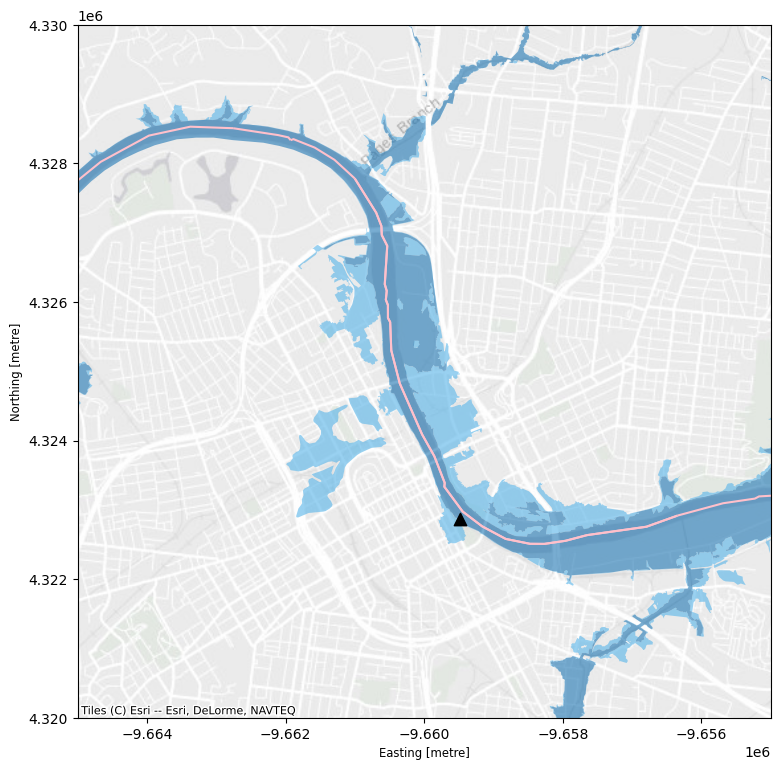

In [35]:
floodplain = gpd.read_file(maps + "davidson_floodplain.zip")
print(floodplain["zone"].unique())

floodplain_w = floodplain.to_crs(epsg=3857)

is_100 = floodplain_w["zone"] == "100-year"
is_500 = floodplain_w["zone"] == "500-year"

fig, ax = plt.subplots(figsize=(9,9))

floodplain_w[is_500].plot(ax=ax, color="#56B4E9", alpha=0.6)
floodplain_w[is_100].plot(ax=ax, color="tab:blue", alpha=0.6)

# add the river, county, gauges, and basemap here
county_w.boundary.plot(ax=ax, color="black", linewidth=1, linestyle="--")
rivers_w.plot(ax=ax, color="pink", linewidth=1.5)
gauges_w.plot(ax=ax, color="black", marker="^", markersize=80, zorder=5)

xmin, ymin, xmax, ymax = county_w.total_bounds
ax.set_xlim(-9.665e6, -9.655e6)
ax.set_ylim(4.32e6, 4.33e6)

cx.add_basemap(ax=ax, source=cx.providers.Esri.WorldGrayCanvas)
#fig.savefig("____", dpi=____, bbox_inches="tight")

#### How would we zoom into downtown Nashville?

----
# Some other plotting, just for fun (might be useful for your projects)

Sometimes, the best thing for you is just a bunch of different examples of how to use things. We'll go through this if we have time. 

In [ ]:
from shapely.geometry import Point, LineString, Polygon, box

In [ ]:
# Load Colorado geology shapefile (can read from .zip directly!)
geology = gpd.read_file(maps + 'geology_a_co.zip')

print(f"Loaded {len(geology)} geologic units")
print(f"Type: {type(geology)}")
print("It's a GeoDataFrame - just like a DataFrame!")
print("\nColumns:", geology.columns.tolist())

In [ ]:
geology.plot(figsize=(16, 8), edgecolor='black', linewidth=0.2)
plt.title('Colorado Geology', fontsize=16, fontweight='bold')
plt.axis('equal')  # Important for spatial data!
plt.show()

### Brief aside: is this projected correctly? Is Colorado *actually* a perfect square? - No!

We can quickly reproject like this:

In [ ]:
geology_utm = geology.to_crs('EPSG:32613')

print("Original CRS:", geology.crs)
print("New CRS:", geology_utm.crs)

# Check if it's projected now
print("\nIs projected?", not geology_utm.crs.is_geographic)

# Check coordinates now\n",
print("First geometry bounds (in meters):")
print(geology_utm.geometry.iloc[0].bounds)

#### Let's visually confirm:

In [ ]:
# Compare the two projections
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Geographic (lat/lon)
geology.plot(ax=ax1, color='lightblue')
ax1.set_title('Geographic CRS (EPSG:4326)\nUnits: degrees')
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')

# Projected (UTM)
geology_utm.plot(ax=ax2, color='lightcoral')
ax2.set_title('Projected CRS (EPSG:32613)\nUnits: meters')
ax2.set_xlabel('Easting (m)')
ax2.set_ylabel('Northing (m)')

plt.tight_layout()
plt.show()

print("Notice: The shape looks slightly different!")
print("The projected version (right) preserves area better for Colorado.")

In [ ]:
# Map colored by rock type
fig, ax = plt.subplots(figsize=(16, 8))
geology_utm.plot(column='ROCKTYPE1',  # Column to color by
             ax=ax,
             legend=True,
             cmap='tab20',  # Colorful categorical colormap
             edgecolor='black',
             linewidth=0.1,
             legend_kwds={'loc': 'center left', 'bbox_to_anchor': (1, 0.5)}
            )
ax.set_title('Colorado Geology by Rock Type', fontsize=18, fontweight='bold')
ax.axis('equal')
ax.axis('off')  # Turn off axis for cleaner look
plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(16, 8))
geology_utm.plot(column='UNIT_AGE',  # Different column!
             ax=ax,
             legend=True,
             cmap='viridis',
             edgecolor='black',
             linewidth=0.1,
             legend_kwds={'loc': 'center left', 'bbox_to_anchor': (1, 0.5)})
ax.set_title('Colorado Geology by Geologic Age', fontsize=18, fontweight='bold')
ax.axis('equal')
ax.axis('off')  # Turn off axis for cleaner look
plt.tight_layout()
plt.show()

### Adding Points
What if we had coordiantes for different Colorado Cities (or sample locations) and we wanted to plot them on top of this?

We can create a list of points by creating a dictionary with the lat/long, making it a DataFrame, and then making it a GeoDataFrame:   

In [ ]:
# Colorado cities
cities_data = {
    'city': ['Denver', 'Boulder', 'Fort Collins', 'Colorado Springs', 'Pueblo'],
    'population': [715522, 108090, 167830, 486600, 111950],
    'lon': [-104.9903, -105.2705, -105.0844, -104.8214, -104.6091],
    'lat': [39.7392, 40.0150, 40.5853, 38.8339, 38.2544]
}

# Create regular DataFrame
cities_df = pd.DataFrame(cities_data)

# Create geometry column
geometry = [Point(xy) for xy in zip(cities_df['lon'], cities_df['lat'])]

# Create GeoDataFrame
cities = gpd.GeoDataFrame(cities_df, geometry=geometry, crs='EPSG:4326') # Note: different CRS, so we're back to just using our "geology" GeoDataFrame
print("Cities GeoDataFrame:")
cities

#### We can add these cities by simply adding a use of `.plot()` to our existing plotting code, but now we reference our new GeoDataFrame.

(Also I added some fancy labels that are ad their lat/long locations)

In [ ]:
# Map colored by rock type
fig, ax = plt.subplots(figsize=(16, 8))
geology.plot(column='ROCKTYPE1',  # Column to color by
             ax=ax,
             legend=True,
             cmap='tab20',  # Colorful categorical colormap
             edgecolor='black',
             linewidth=0.1,
             legend_kwds={'loc': 'center left', 'bbox_to_anchor': (1, 0.5)}
            )
# NEW: adding points where the cities are
cities.plot(ax=ax, color='black', markersize=50, edgecolor='black')

for idx, row in cities.iterrows():
    ax.annotate(row['city'], 
                xy=(row['lon'], row['lat']), 
                xytext=(8, 8), 
                textcoords='offset points',
                fontsize=10, 
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
ax.set_title('Colorado Geology by Rock Type', fontsize=18, fontweight='bold')
ax.axis('equal')
ax.axis('off')  # Turn off axis for cleaner look
plt.tight_layout()
plt.show()

#### Because we also have population data, we could even scale the size of the points according to population

In [ ]:
# Map colored by rock type
fig, ax = plt.subplots(figsize=(16, 8))
geology.plot(column='ROCKTYPE1',  # Column to color by
             ax=ax,
             legend=True,
             cmap='tab20',  # Colorful categorical colormap
             edgecolor='black',
             linewidth=0.1,
             legend_kwds={'loc': 'center left', 'bbox_to_anchor': (1, 0.5)}
            )
# NEW: making city markers scaled to population
cities.plot(ax=ax, 
            markersize=cities['population']/1000,  # Scale by population
            color='#ff7f0e',
            alpha=0.7,
            edgecolor='black',
            linewidth=1.5,
            label='Cities (sized by pop.)')
for idx, row in cities.iterrows():
    ax.annotate(row['city'], 
                xy=(row['lon'], row['lat']), 
                xytext=(8, 8), 
                textcoords='offset points',
                fontsize=10, 
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
ax.set_title('Colorado Geology by Rock Type', fontsize=18, fontweight='bold')
ax.axis('equal')
ax.axis('off')  # Turn off axis for cleaner look
plt.tight_layout()
plt.show()

### Adding a Bounding Box & Zooming in
Often, we'll have a lot of spatial data, but will only be concerned with a small portion of it. We can do 2 things to highlight the area of interest:
1. Add a bounding box (polygon)
2. Zoom in to said bounding box

#### 1. Adding a bounding box
To add a bounding box, we need to create a **custom polygon**. We can do that by using the Shapely function `box()`, which takes the following input parameters:
- min in x direction (left boundary)
- min in y direction (bottom boundary)
- max in x direction (right boundary)
- max in y direction (top boundary)

Once we have a `box` created, we can then add it as the `geometry` when creating a GeoDataFrame:

Here's a workflow:

In [ ]:
# Create a box around Boulder County
# box(minx, miny, maxx, maxy)
boulder_box = box(-105.7, 39.9, -105.0, 40.3)

# Make it a GeoDataFrame
boulder_area = gpd.GeoDataFrame(
    {'name': ['Boulder Study Area']},
    geometry=[boulder_box],
    crs='EPSG:4326'
)

print("Boulder study area:")
boulder_area

In [ ]:
# Map colored by rock type
fig, ax = plt.subplots(figsize=(16, 8))
geology.plot(column='ROCKTYPE1',  # Column to color by
             ax=ax,
             legend=True,
             cmap='tab20',  # Colorful categorical colormap
             edgecolor='black',
             linewidth=0.1,
             legend_kwds={'loc': 'center left', 'bbox_to_anchor': (1, 0.5)}
            )
# NEW: to plot just the boundary:
boulder_area.boundary.plot(ax=ax, color='black', linewidth=1, linestyle='--', label='Area of Interest')
# or NEW: to plot the whole polygon:
#boulder_area.plot(ax=ax, color='none', edgecolor='red', linewidth=2, label='Study Area')

cities.plot(ax=ax, 
            markersize=cities['population']/1000,  # Scale by population
            color='#ff7f0e',
            alpha=0.7,
            edgecolor='black',
            linewidth=1.5,
            label='Cities (sized by pop.)')
for idx, row in cities.iterrows():
    ax.annotate(row['city'], 
                xy=(row['lon'], row['lat']), 
                xytext=(8, 8), 
                textcoords='offset points',
                fontsize=10, 
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
ax.set_title('Colorado Geology by Rock Type', fontsize=18, fontweight='bold')
ax.axis('equal')
ax.axis('off')  # Turn off axis for cleaner look
plt.tight_layout()
plt.show()

### Zooming in

In [ ]:
# Set extent to study area
# Map colored by rock type
fig, ax = plt.subplots(figsize=(16, 8))
geology.plot(column='ROCKTYPE1',  # Column to color by
             ax=ax,
             legend=True,
             cmap='tab20',  # Colorful categorical colormap
             edgecolor='black',
             linewidth=0.1,
             legend_kwds={'loc': 'center left', 'bbox_to_anchor': (1, 0.5)}
            )
cities.plot(ax=ax, 
            markersize=cities['population']/1000,  # Scale by population
            color='#ff7f0e',
            alpha=0.7,
            edgecolor='black',
            linewidth=1.5,
            label='Cities (sized by pop.)')
for idx, row in cities.iterrows():
    ax.annotate(row['city'], 
                xy=(row['lon'], row['lat']), 
                xytext=(8, 8), 
                textcoords='offset points',
                fontsize=10, 
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
ax.set_title('Colorado Geology by Rock Type', fontsize=18, fontweight='bold')
# NEW: Replace adding the ax.axis('equal') with these lines:
ax.set_xlim(-105.7, -105.0)
ax.set_ylim(39.9, 40.3)
plt.tight_layout()
plt.show()

## 1.3 Filtering for One Rock Type (just to get data)
We can filter our data using our columns just like in Pandas.

**If we had a DataFrame called `df`, which had a column called `temperatures`, how would we filter for rows where temperature > 30?**

<details> <summary>Answer</summary>

```python
df[df['temperature'] > 30]
```
</details>


**So if we have our new GeoDataFrame called `geology`, we can fileter for just the sandstone rows using a mask:**


In [ ]:
sandstone = geology[geology['ROCKTYPE1'] == 'sandstone']

print(f"Total geologic units: {len(geology)}")
print(f"Sandstone units: {len(sandstone)}")
print(f"Percentage: {100 * len(sandstone) / len(geology):.1f}%")

### And then we can use that in a plot

In [ ]:
# Map colored by rock type
fig, ax = plt.subplots(figsize=(16, 8))

sandstone.plot(ax=ax, color='tan', edgecolor='brown', linewidth=0.5)

cities.plot(ax=ax, color='black', markersize=50, edgecolor='black')

for idx, row in cities.iterrows():
    ax.annotate(row['city'], 
                xy=(row['lon'], row['lat']), 
                xytext=(8, 8), 
                textcoords='offset points',
                fontsize=10, 
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
    
ax.set_title('Sandstone Units in Colorado', fontsize=18, fontweight='bold')
ax.axis('equal')
ax.axis('off')  # Turn off axis for cleaner look
plt.tight_layout()
plt.show()

#### What about mapping **Cretaceous sandstone**?
First, how do we grab the right data?

#### DOUBLE MASK TIME

In [ ]:
cret_sandstone = geology[(geology['ROCKTYPE1'] == 'sandstone') & (geology['UNIT_AGE'] == 'Cretaceous')]

print(f"Cretaceous sandstone units: {len(cret_sandstone)}")
cret_sandstone.head()

In [ ]:
# Map colored by rock type
fig, ax = plt.subplots(figsize=(12, 10))

cret_sandstone.plot(ax=ax, color='gold', edgecolor='brown', linewidth=0.5)

cities.plot(ax=ax, color='black', markersize=50, edgecolor='black')

for idx, row in cities.iterrows():
    ax.annotate(row['city'], 
                xy=(row['lon'], row['lat']), 
                xytext=(8, 8), 
                textcoords='offset points',
                fontsize=10, 
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
ax.set_title('Cretaceous Sandstone in Colorado', fontsize=18, fontweight='bold')
ax.axis('equal')
ax.axis('off')  # Turn off axis for cleaner look
plt.tight_layout()
plt.show()

### Using `isin()` for Multiple Values

#### Let's find the igneous rocks: granite, basalt, etc.

In [ ]:
igneous_types = ['granite', 'basalt', 'gabbro', 'rhyolite', 'andesite']
igneous = geology[geology['ROCKTYPE1'].isin(igneous_types)]
igneous.head()

#### If we want to figure out how many of each type of igneous rock, we can use the Pandas method `.value_counts()`
- `.value_counts()` will count and display the frequency of different rock types in the `igneous` GeoDataFrame.
- It goes through every value in the `'ROCKTYPE1'` column, groups identical values together, and counts how many times each unique rock type appears in the dataset.
- The results are automatically sorted in **descending order** by frequency. Meaning the most common rock type appears first, followed by the second most common, and so on.

In [ ]:
print(f"Igneous rock units {len(igneous)}")
print("Breakdown by type:")
print(igneous['ROCKTYPE1'].value_counts())

#### And now we can easily map these:

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
igneous.plot(column='ROCKTYPE1',
             ax=ax,
             legend=True,
             cmap='Reds',
             edgecolor='black',
             linewidth=0.4,
             legend_kwds={'loc': 'center left', 'bbox_to_anchor': (1, 0.5)})
cities.plot(ax=ax, color='black', markersize=50, edgecolor='black')
for idx, row in cities.iterrows():
    ax.annotate(row['city'], 
                xy=(row['lon'], row['lat']), 
                xytext=(8, 8), 
                textcoords='offset points',
                fontsize=10, 
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

ax.set_title('Igneous Rocks in Colorado', fontsize=16, fontweight='bold')
ax.axis('equal')
ax.axis('off')
plt.tight_layout()
plt.show()

## 1.4 Using `.value_counts()` and `.groupby()`
Again, the theme of this week is that GeoPands works EXACTLY like Pandas.

### Count Rock Types

In [ ]:
rock_counts = geology['ROCKTYPE1'].value_counts()

print("Top 10 most common rock types:")
print(rock_counts.head(10))

### Visualize as a Bar Chart

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
rock_counts.head(10).plot(kind='barh', ax=ax, color='brown')
ax.set_xlabel('Number of Units', fontsize=12)
ax.set_title('Most Common Rock Types in Colorado', fontsize=14, fontweight='bold')
ax.invert_yaxis()  # Flip so largest is on top
plt.tight_layout()
plt.show()

### Count by Geologic Age

In [ ]:
age_counts = geology['UNIT_AGE'].value_counts()

print("Top 10 geologic ages:")
print(age_counts.head(10))